# The Figure-Eight Orbit, Found by Optimization

Three equal masses ($G = m = 1$) move in a plane with period $T$. Their action is

$$S[q] = \int_0^T \Big[\sum_i \tfrac12 |\dot q_i|^2 + \sum_{i<j} \frac{1}{|q_i - q_j|}\Big]\,dt .$$

Newton's equations are $\delta S = 0$, so every stationary point of $S$ among $T$-periodic paths
is a real orbit. We find orbits without integrating anything. Each path is written as a Fourier
series, and we minimize $S$ over the coefficients.

The bodies share one **choreography** curve, $q_j(t) = q(t + jT/3)$. All three pairs then give
the same integral:

$$S = 3\int_0^T \Big[\tfrac12|\dot q|^2 + \frac{1}{|q(t) - q(t+T/3)|}\Big]\,dt .$$

Modes with $3 \mid k$ are left out, because they move the centre of mass. Two bases are used.

- **The eight subspace.** $x$ gets the odd-$k$ sines and $y$ the even-$k$ sines, with $k \le 45$.
  That makes 30 coefficients.
- **Every choreography.** Both $\cos$ and $\sin$ for $x$ and $y$, with $k \le 30$. That makes
  80 coefficients.

$T = 6.32591398$ is Simó's period, so the numbers compare without rescaling.

Unlike the manual day's integer packing, this objective is smooth and has an exact gradient.
The question running through the notebook is how much that gradient buys you.

The code lives in three modules.

- `figure_eight.py`: the bases, the action, its gradient written out by hand, and the Hessian.
- `optimizers.py`: the optimizers, all hand-written in numpy.
- `reference.py`: the reference answers and the RK4 check.

The fast unit checks are in `test_figure_eight.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from figure_eight import T, OMEGA, eight_basis, choreo_basis, action, random_start
from reference import lagrange_action, lagrange_coeffs, S_STAR

checks = {}
def check(name, ok):
    checks[name] = bool(ok)
    print(f"CHECK {name}:", "PASS" if ok else "FAIL")

eight, choreo = eight_basis(K=45), choreo_basis(K=30)
print(f"eight subspace: {len(eight.k)} coefficients, N = {eight.N} time samples")
print(f"choreography space: {len(choreo.k)} coefficients, N = {choreo.N} time samples")

eight subspace: 30 coefficients, N = 540 time samples
choreography space: 80 coefficients, N = 360 time samples


## 1. The action and its gradient

The kinetic term is exact in Fourier space, $3\cdot\tfrac12 (k\omega)^2 c_k^2 \cdot T/2$ per mode.
The potential term is a Riemann sum over $N$ equally spaced times. The integrand is periodic, so
that sum is spectrally accurate. $N$ is divisible by 3, so the $T/3$ shift is an `np.roll`.

The gradient is written out by hand. With $d_n = q(t_n) - q(t_n + T/3)$, the potential part comes
from $\partial(1/|d|)/\partial d = -d/|d|^3$. Each $d_n$ involves sample $n$ and sample $n + N/3$,
so the gradient gets rolled back before going through the basis matrices.

In [2]:
def fd_grad(c, basis, eps=1e-6):
    return np.array([(action(c + eps * e, basis)[0] - action(c - eps * e, basis)[0]) / (2 * eps)
                     for e in np.eye(len(c))])

for name, basis in (("eight", eight), ("choreo", choreo)):
    c = random_start(basis, np.random.default_rng(0))
    g, gn = action(c, basis)[1], fd_grad(c, basis)
    rel = np.abs(g - gn).max() / np.abs(gn).max()
    print(f"{name:7s} gradient vs central differences: max relative error {rel:.1e}")
    check(f"1a-{name} (analytic gradient matches finite differences, rel. err < 1e-6)", rel < 1e-6)

eight   gradient vs central differences: max relative error 9.0e-10
CHECK 1a-eight (analytic gradient matches finite differences, rel. err < 1e-6): PASS
choreo  gradient vs central differences: max relative error 1.7e-10
CHECK 1a-choreo (analytic gradient matches finite differences, rel. err < 1e-6): PASS


**An exact anchor: the Lagrange circle.** The three bodies sit on an equilateral triangle that
rotates rigidly. Gravity has to supply the centripetal force, $1/(\sqrt3 R^2) = \omega^2 R$, which
gives $R^3 = 1/(\sqrt3\,\omega^2)$ and

$$S_L = 3T\big[\tfrac12\omega^2R^2 + 1/(\sqrt3 R)\big] = 19.648667 .$$

The circle is $q = R(\cos\omega t, \sin\omega t)$, which uses two coefficients of the choreography
basis. Its action should match $S_L$, and its gradient should vanish, because it is an orbit.

In [3]:
cL = lagrange_coeffs(choreo)
SL, gL = action(cL, choreo)
print(f"S(circle coefficients) = {SL:.12f}")
print(f"closed form S_L        = {lagrange_action():.12f}   difference {abs(SL - lagrange_action()):.1e}")
print(f"|grad S| at the circle = {np.abs(gL).max():.1e}")
check("1b (Lagrange circle: S matches the closed form to 1e-10)", abs(SL - lagrange_action()) < 1e-10)
check("1c (Lagrange circle is stationary: |grad S| < 1e-10)", np.abs(gL).max() < 1e-10)

S(circle coefficients) = 19.648667424594
closed form S_L        = 19.648667424594   difference 3.6e-15
|grad S| at the circle = 6.7e-15
CHECK 1b (Lagrange circle: S matches the closed form to 1e-10): PASS
CHECK 1c (Lagrange circle is stationary: |grad S| < 1e-10): PASS


## 2. The eight appearing

Start from a random curve in the eight subspace, with $c_k \sim \mathcal N(0,1)/k^2$, and run
BFGS on $S$. Nothing in the procedure knows about Newton's equations or the figure-eight. The
optimizer only lowers the action, and the eight comes out of that.

BFGS: 52 iterations, 124 action+gradient evaluations
S = 24.427048640771   S* = 24.427048640771   S - S* = 0.0e+00   |grad| = 1.2e-06


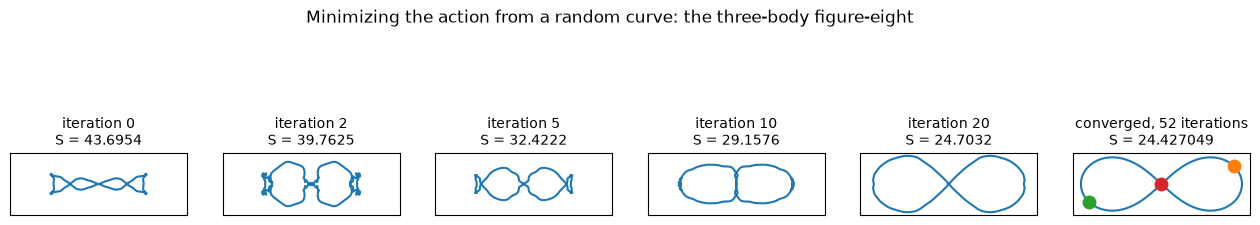

CHECK 2 (BFGS from a random curve reaches S* to 1e-8): PASS


In [4]:
from optimizers import Counter, bfgs

f = Counter(lambda c: action(c, eight))
c8, S8, g8, its = bfgs(f, random_start(eight, np.random.default_rng(4)), scale_H0=True,
                       keep_iterates=True)
print(f"BFGS: {len(its) - 1} iterations, {f.n} action+gradient evaluations")
print(f"S = {S8:.12f}   S* = {S_STAR:.12f}   S - S* = {S8 - S_STAR:.1e}   |grad| = {np.linalg.norm(g8):.1e}")

tt = np.linspace(0, T, 600)
Bx, By = eight.matrices(tt)
show = [0, 2, 5, 10, 20, len(its) - 1]
fig, axes = plt.subplots(1, len(show), figsize=(16, 3.2), sharex=True, sharey=True)
for ax, i in zip(axes, show):
    c = its[i]
    ax.plot(Bx @ c, By @ c, color="C0", lw=1.5)
    ax.set_title(f"iteration {i}\nS = {action(c, eight)[0]:.4f}", fontsize=10)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
ts = np.arange(3) * T / 3
Px, Py = eight.matrices(ts)
for j, col in enumerate(["C3", "C2", "C1"]):
    axes[-1].plot(Px[j] @ c8, Py[j] @ c8, "o", color=col, ms=9)
axes[-1].set_title(f"converged, {len(its) - 1} iterations\nS = {S8:.6f}", fontsize=10)
fig.suptitle("Minimizing the action from a random curve: the three-body figure-eight", y=1.04)
plt.show()
check("2 (BFGS from a random curve reaches S* to 1e-8)", abs(S8 - S_STAR) < 1e-8)

The three dots mark the bodies at $t = 0$. One body is at the crossing point, and the other two
sit symmetrically on the lobes. A third of a period later they have swapped places.

## 3. Is it really the orbit?

A low action is not yet an orbit. Two checks below do not use the optimizer at all.

**First, polish.** BFGS stops near $|\nabla S| \sim 10^{-6}$, where the Armijo test can no longer
resolve changes in $S$. At that point $S$ is already right to $10^{-14}$. The error in $S$ is second
order in the error of the path, so a converged $S$ says little about the path itself.

A couple of Newton steps fix this. The step is $c \to c - H^{-1}\nabla S$, with $H$ obtained by
finite-differencing the analytic gradient. Watch $|\nabla S|$ fall quadratically. That quadratic
rate is what an exact Hessian buys you, and none of the six methods raced below has it.

In [5]:
from figure_eight import hessian_fd, bodies
from optimizers import newton_polish
from reference import (rk4_period, energy, angular_momentum, SIMO_Q1, SIMO_V3, E_EIGHT)

f8 = lambda c: action(c, eight)
c8, norms = newton_polish(f8, lambda c: hessian_fd(c, eight), c8)
print("|grad S| after 0, 1, 2, 3 Newton steps:", "  ".join(f"{x:.1e}" for x in norms))
check("3a (Newton polish: |grad S| < 1e-12)", norms[-1] < 1e-12)

|grad S| after 0, 1, 2, 3 Newton steps: 1.2e-06  9.3e-15  4.0e-15  4.3e-15
CHECK 3a (Newton polish: |grad S| < 1e-12): PASS


**Second, integrate.** Take the three bodies' positions and velocities at $t = 0$. The velocities
come from the analytic derivative of the series. Integrate Newton's equations for one period with
a hand-written RK4, and check that the state comes back to itself. Energy and angular momentum are
checked along the way.

To compare with Simó's numbers, keep in mind that reflecting $x$, reflecting $y$, and reversing time
each map the eight to itself. Which copy the optimizer lands on depends on the random start. So
align the signs first.

In [6]:
q, v = bodies(c8, eight, 0.0)
closure, dE = rk4_period(q, v, n_steps=5000)
E, L = energy(q, v), angular_momentum(q, v)
print("body positions at t = 0:\n", q.round(8))
print(f"RK4 over one period: closure |y(T) - y(0)| = {closure:.1e}, max energy drift = {dE:.1e}")
print(f"E = {E:.8f} (Simo {E_EIGHT}),  L = {L:.1e}")

sx, sy = np.sign(q[1] / SIMO_Q1)               # reflections that map our body at T/3 onto Simo's q_1
q1, v3 = q[1] * [sx, sy], v[0] * [sx, sy]
v3 = v3 * np.sign(v3[0] / SIMO_V3[0])          # time reversal
dq, dv = np.abs(q1 - SIMO_Q1).max(), np.abs(v3 - SIMO_V3).max()
print(f"after aligning signs: |q1 - Simo| = {dq:.1e},  |v3 - Simo| = {dv:.1e}")
check("3b (RK4 closure over one period < 1e-9 at K = 45)", closure < 1e-9)
check("3c (energy conserved to 1e-10, matches Simo's E to 1e-6, L = 0 to 1e-12)",
      dE < 1e-10 and abs(E - E_EIGHT) < 1e-6 and abs(L) < 1e-12)
check("3d (initial conditions match Simo's 8-digit values to 1e-7)", max(dq, dv) < 1e-7)

body positions at t = 0:
 [[ 0.          0.        ]
 [-0.97000436 -0.24308753]
 [ 0.97000436  0.24308753]]
RK4 over one period: closure |y(T) - y(0)| = 1.1e-10, max energy drift = 4.8e-13
E = -1.28714200 (Simo -1.287142),  L = 1.1e-16
after aligning signs: |q1 - Simo| = 3.6e-09,  |v3 - Simo| = 1.5e-09
CHECK 3b (RK4 closure over one period < 1e-9 at K = 45): PASS
CHECK 3c (energy conserved to 1e-10, matches Simo's E to 1e-6, L = 0 to 1e-12): PASS
CHECK 3d (initial conditions match Simo's 8-digit values to 1e-7): PASS


**How fast does it converge in $K$?** Repeat the minimize, polish and integrate steps for several
truncations $K$. Plot the error in $S$ and the RK4 closure error, which is a measure of the error
in the path, on the same axes.

K =  4 ( 3 coefficients):  S - S* = 8.5e-02   closure = 3.5e+00


K =  6 ( 4 coefficients):  S - S* = 1.1e-02   closure = 1.7e+00


K = 10 ( 7 coefficients):  S - S* = 1.2e-04   closure = 1.3e-01


K = 15 (10 coefficients):  S - S* = 7.3e-07   closure = 3.6e-04


K = 20 (14 coefficients):  S - S* = 1.4e-09   closure = 1.6e-05


K = 30 (20 coefficients):  S - S* = 1.4e-13   closure = 4.7e-06


K = 45 (30 coefficients):  S - S* = 0.0e+00   closure = 1.1e-10


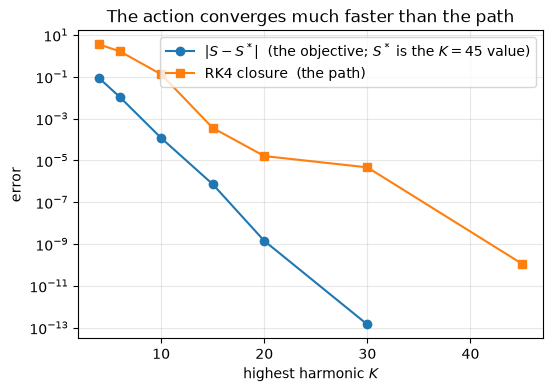

CHECK 3e (S converges spectrally: |S - S*| < 1e-8 by K = 20): PASS
CHECK 3f (S error is far below the path error at every K >= 10): PASS


In [7]:
Ks = [4, 6, 10, 15, 20, 30, 45]
dS, clo = [], []
for K in Ks:
    b = eight_basis(K)
    fK = lambda c: action(c, b)
    c, S, g = bfgs(fK, random_start(b, np.random.default_rng(4)), scale_H0=True)
    c, _ = newton_polish(fK, lambda c: hessian_fd(c, b), c)
    dS.append(abs(fK(c)[0] - S_STAR)); clo.append(rk4_period(*bodies(c, b, 0.0))[0])
    print(f"K = {K:2d} ({len(b.k):2d} coefficients):  S - S* = {dS[-1]:.1e}   closure = {clo[-1]:.1e}")

plt.figure(figsize=(6, 4))
plt.semilogy(Ks[:-1], dS[:-1], "o-", label=r"$|S - S^*|$  (the objective; $S^*$ is the $K = 45$ value)")
plt.semilogy(Ks, clo, "s-", label="RK4 closure  (the path)")
plt.xlabel("highest harmonic $K$"); plt.ylabel("error")
plt.title("The action converges much faster than the path")
plt.legend(); plt.grid(alpha=0.3); plt.show()
i20 = Ks.index(20)
check("3e (S converges spectrally: |S - S*| < 1e-8 by K = 20)", dS[i20] < 1e-8)
check("3f (S error is far below the path error at every K >= 10)",
      all(s < 1e-2 * c for s, c, K in zip(dS, clo, Ks) if K >= 10))

At $K = 20$ the action is already right to about $10^{-9}$, but the path only closes to about
$10^{-5}$. Roughly, the error in $S$ is the square of the error in the path. That happens because
$S$ is *stationary* at the true orbit, and to first order it cannot tell a slightly wrong path
from the right one.

This is good and bad for us as optimizers. The good part: the objective value is very forgiving.
The bad part: a converged $S$ does not certify a converged path. That is why Newton and RK4 are
used above.

## 4. The race

Six optimizers run on the same 30-dimensional objective from the same three random starts:

| method | uses | per step |
|---|---|---|
| random search | $S$ | draw from the $\mathcal N(0,1)/k^2$ prior, keep the best |
| simulated annealing | $S$ | Metropolis move on one coefficient, step $0.05/k^2$, $T: 1 \to 10^{-9}$ |
| gradient descent | $S, \nabla S$ | step along $-\nabla S$, Armijo backtracking |
| preconditioned GD | $S, \nabla S$ | step along $-\nabla S / P$, with $P_k = 3(T/2)(k\omega)^2$ the kinetic Hessian |
| BFGS, $H_0 = I$ | $S, \nabla S$ | quasi-Newton, must learn the metric itself |
| BFGS, scaled $H_0$ | $S, \nabla S$ | after the first step, $H_0 \to (s\cdot y/y\cdot y)\,I$ |

**How cost is counted.** The x-axis counts calls of the objective. For the gradient methods, a
call means the action and its gradient together. The gradient costs about $2\times$ the action alone
(measured below), so the comparison is fair to within a factor of 2. The gaps we will see are
orders of magnitude.

In [8]:
import time
from figure_eight import kinetic_diag
from optimizers import gradient_descent, random_search, simulated_annealing

t_S = time.perf_counter(); [action(c8, eight, grad=False) for _ in range(2000)]; t_S = time.perf_counter() - t_S
t_g = time.perf_counter(); [action(c8, eight) for _ in range(2000)]; t_g = time.perf_counter() - t_g
print(f"cost of one call: S alone {t_S * 500:.0f} us, S + gradient {t_g * 500:.0f} us  (ratio {t_g / t_S:.1f})")

P = kinetic_diag(eight)
seeds = [0, 1, 2]
methods = {
    "random search":       lambda c0, rng, f: random_search(f, lambda: random_start(eight, rng), 100_000),
    "simulated annealing": lambda c0, rng, f: simulated_annealing(f, c0, 1 / eight.k**2, rng),
    "gradient descent":    lambda c0, rng, f: gradient_descent(f, c0),
    "preconditioned GD":   lambda c0, rng, f: gradient_descent(f, c0, precond=P),
    "BFGS, H0 = I":        lambda c0, rng, f: bfgs(f, c0),
    "BFGS, scaled H0":     lambda c0, rng, f: bfgs(f, c0, scale_H0=True),
}
gradient_free = {"random search", "simulated annealing"}
race = {}
for name, run in methods.items():
    t0 = time.perf_counter()
    race[name] = []
    for seed in seeds:
        rng = np.random.default_rng(seed)
        c0 = random_start(eight, rng)
        f = Counter((lambda c: action(c, eight, grad=False)) if name in gradient_free else f8)
        run(c0, rng, f)
        race[name].append(np.array(f.best) - S_STAR)
    print(f"{name:20s} done in {time.perf_counter() - t0:5.1f} s")

cost of one call: S alone 58 us, S + gradient 140 us  (ratio 2.4)


random search        done in  20.8 s


simulated annealing  done in  48.3 s


gradient descent     done in   4.5 s
preconditioned GD    done in   0.1 s


BFGS, H0 = I         done in   0.2 s
BFGS, scaled H0      done in   0.1 s


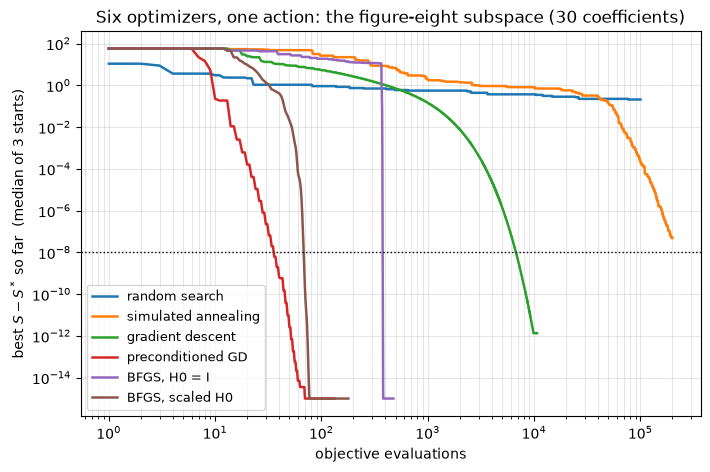

method                   evaluations to reach S - S* < 1e-8 (per start)   final S - S*
random search                                        [None, None, None]   2.1e-01
simulated annealing                                  [None, None, None]   4.8e-08
gradient descent                                     [7485, 6741, 6743]   1.4e-12
preconditioned GD                                          [42, 32, 36]   0.0e+00
BFGS, H0 = I                                            [404, 366, 377]   0.0e+00
BFGS, scaled H0                                           [112, 69, 59]   0.0e+00


In [9]:
def evals_to(curve, tol=1e-8):
    hit = np.nonzero(curve < tol)[0]
    return int(hit[0]) + 1 if len(hit) else None

def median_curve(curves):
    n = max(len(c) for c in curves)
    return np.median([np.r_[c, np.full(n - len(c), c[-1])] for c in curves], axis=0)

plt.figure(figsize=(8, 5))
for name, curves in race.items():
    m = median_curve(curves)
    plt.loglog(np.arange(1, len(m) + 1), np.maximum(m, 1e-15), label=name, lw=1.8)
plt.axhline(1e-8, color="k", ls=":", lw=1)
plt.xlabel("objective evaluations"); plt.ylabel(r"best $S - S^*$ so far  (median of 3 starts)")
plt.title("Six optimizers, one action: the figure-eight subspace (30 coefficients)")
plt.legend(fontsize=9); plt.grid(alpha=0.3, which="both"); plt.show()

print(f"{'method':20s} {'evaluations to reach S - S* < 1e-8 (per start)':>50s}   final S - S*")
counts = {}
for name, curves in race.items():
    counts[name] = [evals_to(c) for c in curves]
    print(f"{name:20s} {str(counts[name]):>50s}   {np.median([c[-1] for c in curves]):.1e}")

### Reading the race

**Random search.** It finds the right basin quickly and then stalls. Here is why. Near the
minimum, $S - S^* \approx \tfrac12 \delta c^T H\, \delta c$. If $d_\text{eff}$ directions matter, the
chance that a random draw lands within $\epsilon$ of $S^*$ scales like the volume of an ellipsoid,
$\propto \epsilon^{d_\text{eff}/2}$. So the best of $n$ draws improves only like
$n^{-2/d_\text{eff}}$. That is the manual day's curse of dimensionality seen from a different
angle. Fitting the measured curve gives the effective dimension.

In [10]:
m = median_curve(race["random search"])
n = np.arange(1, len(m) + 1)
sel = n >= 100
slope = np.polyfit(np.log(n[sel]), np.log(m[sel]), 1)[0]
print(f"random search: best after 1e3, 1e4, 1e5 draws = {m[999]:.2f}, {m[9999]:.2f}, {m[-1]:.2f}")
print(f"fitted best ~ n^({slope:.3f})  ->  d_eff = -2/slope = {-2 / slope:.1f}  (of 30 coefficients)")
check("4a (random search stalls: best S - S* > 1e-2 after 1e5 draws)", m[-1] > 1e-2)

random search: best after 1e3, 1e4, 1e5 draws = 0.56, 0.37, 0.21
fitted best ~ n^(-0.219)  ->  d_eff = -2/slope = 9.1  (of 30 coefficients)
CHECK 4a (random search stalls: best S - S* > 1e-2 after 1e5 draws): PASS


The prior $\mathcal N(0,1)/k^2$ shrinks the high harmonics so hard that they barely matter. That is
why $d_\text{eff}$ comes out far below 30. Even so, a handful of effective dimensions is enough to
make precision unreachable by sampling.

**Simulated annealing** has the same information as random search, the value of $S$ and nothing
more. It does far better because its moves are local and it keeps what works. Even so, it needs
about $10^5$ evaluations to get where the gradient methods get in tens.

**Gradient descent and the condition number.** Steepest descent needs a number of steps of order
the condition number $\kappa$ of the Hessian. Before measuring it, we can predict it. The kinetic term
dominates the Hessian, and it is diagonal with entries $\propto k^2$. That gives
$\kappa \approx (k_\max/k_\min)^2 = 44^2 = 1936$.

In [11]:
H = hessian_fd(c8, eight)
ev = np.linalg.eigvalsh(H)
Pih = 1 / np.sqrt(P)
evp = np.linalg.eigvalsh(Pih[:, None] * H * Pih[None, :])
print(f"predicted (kinetic diagonal): kappa = {P.max() / P.min():.0f}   (lowest entry {P.min():.2f})")
print(f"measured Hessian at S*:       eigenvalues {ev.min():.1f} ... {ev.max():.0f},  kappa = {ev.max() / ev.min():.0f}")
print(f"after preconditioning by P:   kappa = {evp.max() / evp.min():.2f}")
gd, pgd = np.median(counts["gradient descent"]), np.median(counts["preconditioned GD"])
print(f"evaluations to 1e-8: plain GD {gd:.0f}, preconditioned GD {pgd:.0f}, ratio {gd / pgd:.0f}")
check("4b (measured kappa within a factor 3 of the kinetic prediction 1936)", 1936 / 3 < ev.max() / ev.min() < 1936 * 3)
check("4c (preconditioning brings kappa below 10)", evp.max() / evp.min() < 10)
check("4d (preconditioned GD reaches 1e-8 in < 100 evaluations from every start)",
      all(c is not None and c < 100 for c in counts["preconditioned GD"]))
check("4e (plain GD needs > 20x the evaluations of preconditioned GD)", gd > 20 * pgd)

predicted (kinetic diagonal): kappa = 1936   (lowest entry 9.36)
measured Hessian at S*:       eigenvalues 21.8 ... 18135,  kappa = 833
after preconditioning by P:   kappa = 3.78
evaluations to 1e-8: plain GD 6743, preconditioned GD 36, ratio 187
CHECK 4b (measured kappa within a factor 3 of the kinetic prediction 1936): PASS
CHECK 4c (preconditioning brings kappa below 10): PASS
CHECK 4d (preconditioned GD reaches 1e-8 in < 100 evaluations from every start): PASS
CHECK 4e (plain GD needs > 20x the evaluations of preconditioned GD): PASS


The prediction gets the order of magnitude right but overshoots by about a factor of 2. The
potential is the reason. It adds positive curvature to the slow, low-$k$ modes, and that raises the
smallest eigenvalue from the kinetic $9.4$ to about $22$.

Preconditioning by the kinetic diagonal is one line of code, and it takes $\kappa$ from
roughly $800$ to roughly $4$. It amounts to stepping in the metric that the kinetic energy defines.
Here the physics tells you the geometry of the problem for free.

**BFGS** builds an approximate inverse Hessian from the gradients it sees, so it learns the metric
on its own. Started from $H_0 = I$, its curve in the race has two distinct phases.

- **Learning the metric.** For about 350 evaluations it makes slow progress. In the identity
  metric a unit trial step is wildly too long for the high-$k$ modes. Each iteration therefore
  spends about ten evaluations on backtracking halvings, and the curvature is collected one secant
  pair at a time.
- **Superlinear convergence.** Once $H$ is a good enough approximation to $\nabla^2 S^{-1}$, the
  run drops from $S - S^* \approx 40$ to machine precision in about 30 evaluations.

The one-line rescaling of $H_0$ shortens the learning phase a lot. It still does not beat the
metric that the physics hands you for free.

In [12]:
b_id, b_sc = np.median(counts["BFGS, H0 = I"]), np.median(counts["BFGS, scaled H0"])
sa_final = [c[-1] for c in race["simulated annealing"]]
print(f"evaluations to 1e-8: BFGS H0=I {b_id:.0f}, BFGS scaled {b_sc:.0f}, preconditioned GD {pgd:.0f}")
print("simulated annealing, final S - S* per start:", "  ".join(f"{x:.1e}" for x in sa_final))
check("4f (scaling H0 cuts BFGS's evaluations by > 2x)", b_id > 2 * b_sc)
check("4g (simulated annealing reaches S - S* < 1e-6 from every start, with 2e5 evaluations)",
      max(sa_final) < 1e-6)

evaluations to 1e-8: BFGS H0=I 377, BFGS scaled 69, preconditioned GD 36
simulated annealing, final S - S* per start: 3.6e-08  4.8e-08  5.5e-08
CHECK 4f (scaling H0 cuts BFGS's evaluations by > 2x): PASS
CHECK 4g (simulated annealing reaches S - S* < 1e-6 from every start, with 2e5 evaluations): PASS


**The upshot.** On a smooth objective the gradient is worth four orders of magnitude in evaluations.
Within the gradient methods, conditioning matters most. A metric supplied by the physics, the
preconditioned GD, beats one that BFGS learns on the fly. Gradient-free methods earn their place
when the objective is integer-valued, like the manual day's packing, or when it is too rough to
differentiate. They do not earn it here.

## 5. The landscape without the symmetry

So far the search ran in the eight subspace. Its basis has the figure-eight's reflection symmetries
built in. Now drop them. Allow every choreography, with $\cos$ and $\sin$ for both $x$ and $y$ and
$k \le 30$. That is 80 coefficients. Run BFGS from 100 random starts and look at where each run
ends.

100 BFGS runs in 5.0 s
Lagrange circle (S = 19.6487): 77   figure-eight (S = 24.4270): 23   other: 0
CHECK 5a (every one of 100 starts ends on the circle or the eight): PASS
CHECK 5b (both basins are hit: the circle in 60-90 starts, the eight in the rest): PASS


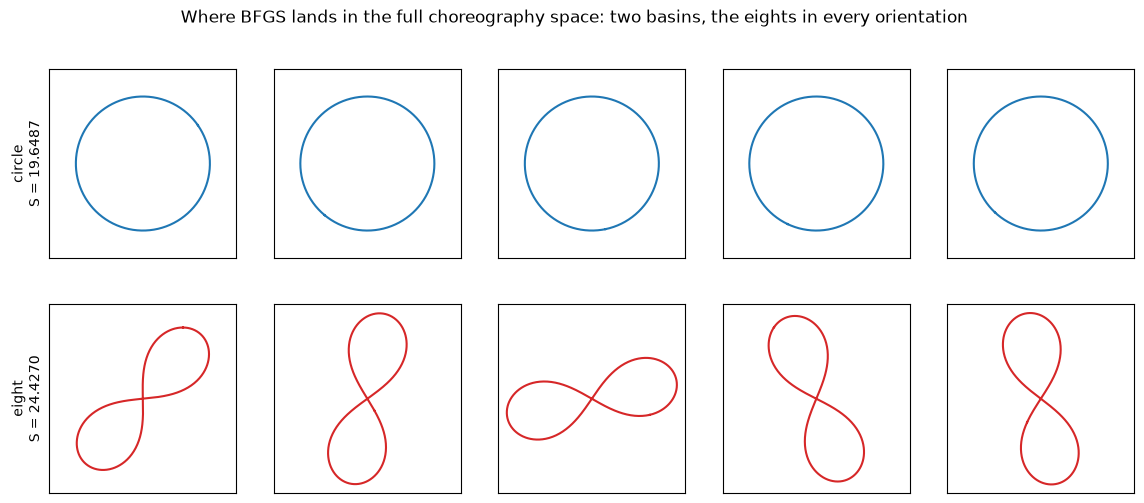

In [13]:
fc = lambda c: action(c, choreo)
SL = lagrange_action()
ends = {"circle": [], "eight": [], "other": []}
t0 = time.perf_counter()
for seed in range(100):
    c, S, g = bfgs(fc, random_start(choreo, np.random.default_rng(seed)), scale_H0=True)
    key = "circle" if abs(S - SL) < 1e-5 else "eight" if abs(S - S_STAR) < 1e-5 else "other"
    ends[key].append(c)
    if key == "other":
        print(f"seed {seed}: ended at S = {S:.6f}, |grad| = {np.linalg.norm(g):.1e}")
print(f"100 BFGS runs in {time.perf_counter() - t0:.1f} s")
print(f"Lagrange circle (S = {SL:.4f}): {len(ends['circle'])}   figure-eight (S = {S_STAR:.4f}): "
      f"{len(ends['eight'])}   other: {len(ends['other'])}")
check("5a (every one of 100 starts ends on the circle or the eight)", len(ends["other"]) == 0)
check("5b (both basins are hit: the circle in 60-90 starts, the eight in the rest)",
      60 <= len(ends["circle"]) <= 90 and len(ends["eight"]) == 100 - len(ends["circle"]))

Bx, By = choreo.matrices(tt)
fig, axes = plt.subplots(2, 5, figsize=(14, 5.6), sharex=True, sharey=True)
for row, key in enumerate(["circle", "eight"]):
    for ax, c in zip(axes[row], ends[key]):
        ax.plot(Bx @ c, By @ c, lw=1.5, color="C0" if key == "circle" else "C3")
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    axes[row, 0].set_ylabel(f"{key}\nS = {SL if key == 'circle' else S_STAR:.4f}")
fig.suptitle("Where BFGS lands in the full choreography space: two basins, the eights in every orientation")
plt.show()

Every eight comes out at a different angle. In this space a rotation of a solution is another
solution, and so is a shift in time. These two continuous symmetries should show up as exact **zero
eigenvalues** of the Hessian. Two are expected for the eight. The circle should have only one,
because rotating a circle and shifting it in time are the same motion.

Counting the zero modes is a sharp test of the basis and the gradient. It also decides whether
these points are genuine minima. Apart from the zero modes, every eigenvalue must be positive.

In [14]:
zero_modes = {}
for key in ("circle", "eight"):
    ev = np.linalg.eigvalsh(hessian_fd(ends[key][0], choreo))
    zero_modes[key] = int(np.sum(np.abs(ev) < 1e-2))
    pos = ev[np.abs(ev) >= 1e-2]
    print(f"{key:6s}: lowest eigenvalues {np.round(ev[:4], 4)}   -> {zero_modes[key]} zero mode(s), "
          f"smallest nonzero {pos.min():.2f}, any negative: {bool(np.any(pos < 0))}")
    check(f"5c-{key} (Hessian: {2 if key == 'eight' else 1} zero mode(s), all others positive)",
          zero_modes[key] == (2 if key == "eight" else 1) and np.all(pos > 0))

circle: lowest eigenvalues [-0.     14.0417 14.0417 28.0834]   -> 1 zero mode(s), smallest nonzero 14.04, any negative: False
CHECK 5c-circle (Hessian: 1 zero mode(s), all others positive): PASS
eight : lowest eigenvalues [-0.      0.     18.1035 21.7641]   -> 2 zero mode(s), smallest nonzero 18.10, any negative: False
CHECK 5c-eight (Hessian: 2 zero mode(s), all others positive): PASS


Both are genuine local minima. The eight has its two zero modes, from rotation and from time
shift. The circle has one.

**The lesson for the race.** The eight is a local minimum here, but it is **not** the global one.
The Lagrange circle has lower action, $19.65 < 24.43$. A local method like BFGS lands in whichever
basin it starts in, so it finds the eight about a quarter of the time. A *better* global optimizer
would do worse at our actual task: it would return the circle every time. It was the constraint,
the eight subspace, that selected the orbit we wanted. How hard you optimize did not.

Push Harder below tests that claim directly.

## 6. Push Harder: a good global optimizer finds the wrong answer

Run simulated annealing in the 80-dimensional choreography space, at two settings, with seeds 0–2
and $2\times10^5$ evaluations each.

- **Hot:** $T_0 = 10$, step $0.2/k^2$. The temperature is high enough to carry the walker over the
  barrier between the two basins.
- **Cold:** $T_0 = 1$, step $0.05/k^2$. These are the settings that worked so well in the eight
  subspace in Section 4.

If the claim at the end of Section 5 is right, the hot run should return the circle every time.

hot  (T0 = 10, step 0.2/k^2)  seed 0: S = 19.648670  -> circle (20 s)


hot  (T0 = 10, step 0.2/k^2)  seed 1: S = 19.648670  -> circle (23 s)


hot  (T0 = 10, step 0.2/k^2)  seed 2: S = 19.648672  -> circle (19 s)


cold (T0 = 1, step 0.05/k^2)  seed 0: S = 24.427049  -> eight  (19 s)


cold (T0 = 1, step 0.05/k^2)  seed 1: S = 19.648668  -> circle (19 s)


cold (T0 = 1, step 0.05/k^2)  seed 2: S = 24.427049  -> eight  (19 s)


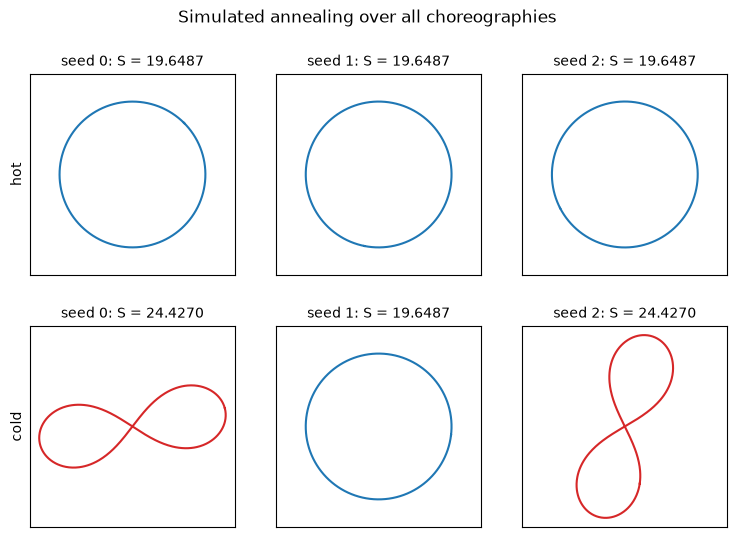

CHECK 6 (hot annealing returns the Lagrange circle from every seed, S to 1e-4): PASS


In [15]:
fs = lambda c: action(c, choreo, grad=False)
settings = {"hot  (T0 = 10, step 0.2/k^2)": (10.0, 0.2), "cold (T0 = 1, step 0.05/k^2)": (1.0, 0.05)}
sa_ends = {}
for label, (T0, step) in settings.items():
    sa_ends[label] = []
    for seed in range(3):
        t0 = time.perf_counter()
        rng = np.random.default_rng(seed)
        c, S = simulated_annealing(fs, random_start(choreo, rng), 1 / choreo.k**2, rng, T0=T0, step=step)
        sa_ends[label].append((c, S))
        name = "circle" if abs(S - SL) < 1e-4 else "eight" if abs(S - S_STAR) < 1e-4 else "?"
        print(f"{label}  seed {seed}: S = {S:.6f}  -> {name:6s} ({time.perf_counter() - t0:.0f} s)")

fig, axes = plt.subplots(2, 3, figsize=(9, 6), sharex=True, sharey=True)
for row, (label, runs) in enumerate(sa_ends.items()):
    for col, (c, S) in enumerate(runs):
        ax = axes[row, col]
        ax.plot(Bx @ c, By @ c, lw=1.5, color="C0" if abs(S - SL) < 1e-4 else "C3")
        ax.set_title(f"seed {col}: S = {S:.4f}", fontsize=10)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    axes[row, 0].set_ylabel(label.split("(")[0].strip())
fig.suptitle("Simulated annealing over all choreographies")
plt.show()
hot = list(sa_ends.values())[0]
check("6 (hot annealing returns the Lagrange circle from every seed, S to 1e-4)",
      all(abs(S - SL) < 1e-4 for _, S in hot))

Hot annealing does what a global optimizer is supposed to do. It finds the lowest action every
time, and that minimum is the circle. Cold annealing sometimes returns the eight, but only because
it starts too cold to leave the basin it falls into first. It is behaving like a randomized local
search.

**The punchline.** The figure-eight is a local minimum of the action among all choreographies. It is
the global minimum only inside its own symmetry class. You get it by choosing the *space* you
search, and that space is the eight subspace of Section 2. Choosing a stronger optimizer does not
get you there. A stronger one takes you straight to the circle. The objective, together with the
space it is defined on, decides which answer counts as "best". The optimizer only decides how
quickly you get there.

## Summary of checks

In [16]:
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\n{sum(checks.values())}/{len(checks)} passed")

PASS  1a-eight (analytic gradient matches finite differences, rel. err < 1e-6)
PASS  1a-choreo (analytic gradient matches finite differences, rel. err < 1e-6)
PASS  1b (Lagrange circle: S matches the closed form to 1e-10)
PASS  1c (Lagrange circle is stationary: |grad S| < 1e-10)
PASS  2 (BFGS from a random curve reaches S* to 1e-8)
PASS  3a (Newton polish: |grad S| < 1e-12)
PASS  3b (RK4 closure over one period < 1e-9 at K = 45)
PASS  3c (energy conserved to 1e-10, matches Simo's E to 1e-6, L = 0 to 1e-12)
PASS  3d (initial conditions match Simo's 8-digit values to 1e-7)
PASS  3e (S converges spectrally: |S - S*| < 1e-8 by K = 20)
PASS  3f (S error is far below the path error at every K >= 10)
PASS  4a (random search stalls: best S - S* > 1e-2 after 1e5 draws)
PASS  4b (measured kappa within a factor 3 of the kinetic prediction 1936)
PASS  4c (preconditioning brings kappa below 10)
PASS  4d (preconditioned GD reaches 1e-8 in < 100 evaluations from every start)
PASS  4e (plain GD needs